In [1]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
import tensorflow as tf 
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))
 
module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)
# from src.utils.ds_helper import get_dataset_distribution


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
model_path = os.getenv("MODEL_DIR")

MODEL_NAME = "CXC102.keras"
model = os.path.join(model_path, MODEL_NAME)

train_data_dir = os.path.join(dataset_path, "data02", "train")
test_data_dir = os.path.join(dataset_path, "data02", "test")
val_data_dir = os.path.join(dataset_path, "data02", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data02/train
/Users/joshan/Documents/final-year-project/dataset/data02/test
/Users/joshan/Documents/final-year-project/dataset/data02/val


In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 11873 files belonging to 3 classes.
Found 1392 files belonging to 3 classes.
Found 694 files belonging to 3 classes.


2026-03-05 12:14:27.320276: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-03-05 12:14:27.320329: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-03-05 12:14:27.320350: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-03-05 12:14:27.320649: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-03-05 12:14:27.320683: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [4]:
data_augmentation = models.Sequential([
    layers.RandomRotation(0.05), 
    
    layers.RandomZoom(0.15), 
    
    layers.RandomFlip("horizontal"), 
    
    layers.RandomContrast(0.2), 
    
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1)
])

In [5]:
model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),
    data_augmentation,
    
    # Block 1
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(), # Added
    layers.MaxPooling2D((2, 2)),
    
    # Block 2
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(), # Added
    layers.MaxPooling2D((2, 2)),
    
    # Block 3
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(), # Added
    layers.MaxPooling2D((2, 2)),

    # Block 4
    layers.Conv2D(256, (3, 3), padding='same', activation='relu'), # Bumped to 256
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Modern Head
    layers.GlobalAveragePooling2D(), # Replaced Flatten
    layers.Dense(256, activation='relu'),  
    layers.Dropout(0.5), 
    layers.Dense(3, activation='softmax')
])

/Users/joshan/Documents/final-year-project/backend/.venv/lib/python3.11/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
import keras


# Define the early stopping monitor
# This stops training if 'val_loss' doesn't improve for 3 epochs
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=3, 
    restore_best_weights=True
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds, # evaluating against val dataset
    epochs=10
)

Epoch 1/10


372/372 ━━━━━━━━━━━━━━━━━━━━ 133s 346ms/step - accuracy: 0.6741 - loss: 0.7956 - val_accuracy: 0.3372 - val_loss: 2.9280
Epoch 2/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 126s 339ms/step - accuracy: 0.7489 - loss: 0.6431 - val_accuracy: 0.6369 - val_loss: 0.8852
Epoch 3/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 126s 337ms/step - accuracy: 0.7745 - loss: 0.6061 - val_accuracy: 0.7349 - val_loss: 0.8073
Epoch 4/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 5919s 16s/step - accuracy: 0.8007 - loss: 0.5594 - val_accuracy: 0.7277 - val_loss: 0.7526
Epoch 5/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 12436s 31s/step - accuracy: 0.8151 - loss: 0.4981 - val_accuracy: 0.8588 - val_loss: 0.3594
Epoch 6/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 13978s 38s/step - accuracy: 0.8251 - loss: 0.4889 - val_accuracy: 0.6585 - val_loss: 2.3336
Epoch 7/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 4621s 12s/step - accuracy: 0.8367 - loss: 0.4530 - val_accuracy: 0.8386 - val_loss: 0.4106
Epoch 8/10
339/372 ━━━━━━━━━━━━━━━━━━━━ 11s 336ms/step - accuracy: 0.8427 - loss: 0.4333

KeyboardInterrupt: 

In [6]:
# Save the model
model.save('CXC102.keras')
print("Model saved successfully!")

Model saved successfully!


In [44]:
# model_path = os.getenv("MODEL_DIR")
model = os.path.join("CXC102.keras")
print(model)
model = tf.keras.models.load_model(model)


CXC102.keras


In [45]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.9102 - loss: 0.8837
Test Loss: 0.8837059140205383
Test Accuracy: 91.02%


2026-03-04 21:31:54.748357: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


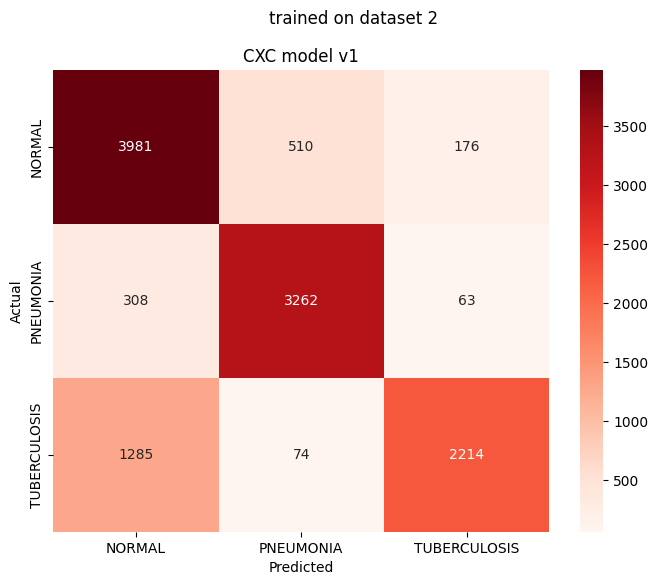

              precision    recall  f1-score   support

      NORMAL       0.71      0.85      0.78      4667
   PNEUMONIA       0.85      0.90      0.87      3633
TUBERCULOSIS       0.90      0.62      0.73      3573

    accuracy                           0.80     11873
   macro avg       0.82      0.79      0.79     11873
weighted avg       0.81      0.80      0.79     11873



In [8]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get all predictions and true labels
y_pred = []
y_true = []

for images, labels in train_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels, axis=1))

# Generate the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
class_names = test_ds.class_names

# Plot them in heat map
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CXC model v1')
plt.suptitle("trained on dataset 2")
plt.show()

# Print Precision, Recall, and F1-Score
print(classification_report(y_true, y_pred, target_names=class_names))

In [16]:
# model_path = os.getenv("MODEL_DIR")
model = os.path.join("CXC102.keras")
print(model)
model = tf.keras.models.load_model(model)


CXC102.keras


In [17]:
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.9102 - loss: 0.8837
Test Loss: 0.8837059140205383
Test Accuracy: 91.02%


In [18]:
# model_path = os.getenv("MODEL_DIR")
model = os.path.join(model_path, "CXC1.keras")
print(model)
model = tf.keras.models.load_model(model)


/Users/joshan/Documents/final-year-project/models/CXC/CXC1.keras


In [19]:
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.9045 - loss: 5.7636
Test Loss: 5.763561248779297
Test Accuracy: 90.45%


In [21]:
import numpy as np
from tensorflow.keras.preprocessing import image

def test_image(path):
    # 1. Load the image and resize it to match your model's input_shape
    img = image.load_img(path, target_size=(224, 224))
    
    # 2. Convert the image to a numpy array
    img_array = image.img_to_array(img)
    
    # 3. Expand dimensions to create a "batch" of one: (1, 224, 224, 3)
    img_batch = np.expand_dims(img_array, axis=0)
    
    # 4. Predict
    predictions = model.predict(img_batch)
    
    # 5. Print the raw probability scores
    print(f"Predictions for {path}:")
    print(predictions)
    
    # Optional: Print the class with the highest probability
    class_idx = np.argmax(predictions[0])
    conf_score = np.max(predictions[0]) * 100
    print(f"Detected Class: {class_idx} ({conf_score:.2f}% confidence)")

# Example usage:
# test_image('path_to_your_test_image.jpg')

In [24]:
test_image('/Users/joshan/Desktop/sdfsds.jpg')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Predictions for /Users/joshan/Desktop/sdfsds.jpg:
[[1. 0. 0.]]
Detected Class: 0 (100.00% confidence)
